In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [19]:
class Encoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.feature_extractor = nn.Sequential(
      nn.Conv2d(1, 32, 4, stride=2, padding=1),
      nn.ReLU(),
      nn.Conv2d(32, 64, 4, stride=2, padding=1),
      nn.ReLU(),
      nn.Conv2d(64, 128, 3, stride=1, padding=0),
      nn.ReLU()
    )
    self.fc = nn.Linear(128 * 5 * 5, 32)

  def forward(self, x):
    x = self.feature_extractor(x)
    x = x.view(x.size(0), -1)
    return self.fc(x)

device = "cuda" if torch.cuda.is_available() else "cpu"

In [20]:
GITHUB_LINK = 'https://github.com/csinva/gan-vae-pretrained-pytorch/tree/master'

In [21]:
class Generator(nn.Module):
    def __init__(self, ngpu, nc=1, nz=100, ngf=64):
        super(Generator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # input is Z, going into a convolution
            nn.ConvTranspose2d(     nz, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # state size. (ngf*8) x 4 x 4
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # state size. (ngf*4) x 8 x 8
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # state size. (ngf*2) x 16 x 16
            nn.ConvTranspose2d(ngf * 2,     ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            nn.ConvTranspose2d(    ngf,      nc, kernel_size=1, stride=1, padding=2, bias=False),
            nn.Tanh()
        )

    def forward(self, input):
        if input.is_cuda and self.ngpu > 1:
            output = nn.parallel.data_parallel(self.main, input, range(self.ngpu))
        else:
            output = self.main(input)
        return output


class Discriminator(nn.Module):
    def __init__(self, ngpu, nc=1, ndf=64):
        super(Discriminator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # input is (nc) x 64 x 64
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf) x 32 x 32
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*2) x 16 x 16
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*4) x 8 x 8
            nn.Conv2d(ndf * 4, 1, 4, 2, 1, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input):
        if input.is_cuda and self.ngpu > 1:
            output = nn.parallel.data_parallel(self.main, input, range(self.ngpu))
        else:
            output = self.main(input)
        return output.view(-1, 1).squeeze(1)

In [22]:
!wget https://github.com/csinva/gan-vae-pretrained-pytorch/raw/master/mnist_dcgan/weights/netG_epoch_99.pth -O netG.pth
!wget https://github.com/csinva/gan-vae-pretrained-pytorch/raw/master/mnist_dcgan/weights/netD_epoch_99.pth -O netD.pth

--2025-11-24 19:19:12--  https://github.com/csinva/gan-vae-pretrained-pytorch/raw/master/mnist_dcgan/weights/netG_epoch_99.pth
Resolving github.com (github.com)... 140.82.113.4
Connecting to github.com (github.com)|140.82.113.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/csinva/gan-vae-pretrained-pytorch/master/mnist_dcgan/weights/netG_epoch_99.pth [following]
--2025-11-24 19:19:12--  https://raw.githubusercontent.com/csinva/gan-vae-pretrained-pytorch/master/mnist_dcgan/weights/netG_epoch_99.pth
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14306386 (14M) [application/octet-stream]
Saving to: ‘netG.pth’

netG.pth            100%[===================>]  13.64M  --.-KB/s    in 0.03s   

2025

In [23]:
ngpu = 1
device = "cuda"

netG = Generator(ngpu=ngpu, nc=1, nz=100, ngf=64).to(device)
netD = Discriminator(ngpu=ngpu, nc=1, ndf=64).to(device)

G_state = torch.load("netG.pth", map_location=device)
D_state = torch.load("netD.pth", map_location=device)

netG.load_state_dict(G_state)
netD.load_state_dict(D_state)

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

class MNIST_Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*7*7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.fc(self.conv(x))

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.ToTensor()
])

train_ds = datasets.MNIST("./data", train=True, download=True, transform=transform)
test_ds  = datasets.MNIST("./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False)

clf = MNIST_Classifier().to(device)
opt = optim.Adam(clf.parameters(), lr=1e-3)

for epoch in range(3):
    clf.train()
    running = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        out = clf(x)
        loss = F.cross_entropy(out, y)
        loss.backward()
        opt.step()
        running += loss.item()*x.size(0)

    print(f"Epoch {epoch+1} Loss: {running/len(train_loader.dataset):.4f}")

clf.eval()
correct=0
total=0

with torch.no_grad():
    for x,y in test_loader:
        x,y = x.to(device), y.to(device)
        out = clf(x)
        pred = out.argmax(1)
        correct += (pred==y).sum().item()
        total += y.size(0)

print("Test accuracy:", correct/total)


Epoch 1 Loss: 0.2543
Epoch 2 Loss: 0.0615
Epoch 3 Loss: 0.0421
Test accuracy: 0.9869


0: 5.63%
1: 10.62%
2: 11.60%
3: 11.72%
4: 14.78%
5: 11.96%
6: 13.48%
7: 9.23%
8: 6.71%
9: 4.27%
[E1 S0] kept 247/256
[E1 S100] kept 244/256
[E1 S200] kept 241/256
[E1 S300] kept 239/256
[Epoch 1] % Digit 0 = 4.97%


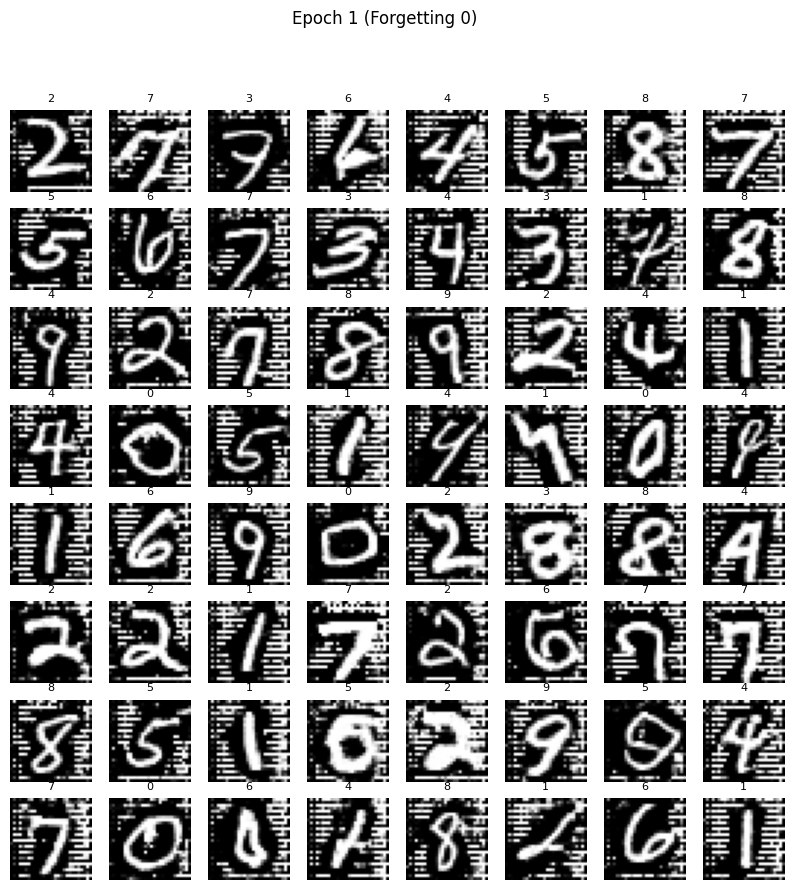

[E2 S0] kept 245/256
[E2 S100] kept 247/256
[E2 S200] kept 243/256
[E2 S300] kept 241/256
[Epoch 2] % Digit 0 = 4.57%


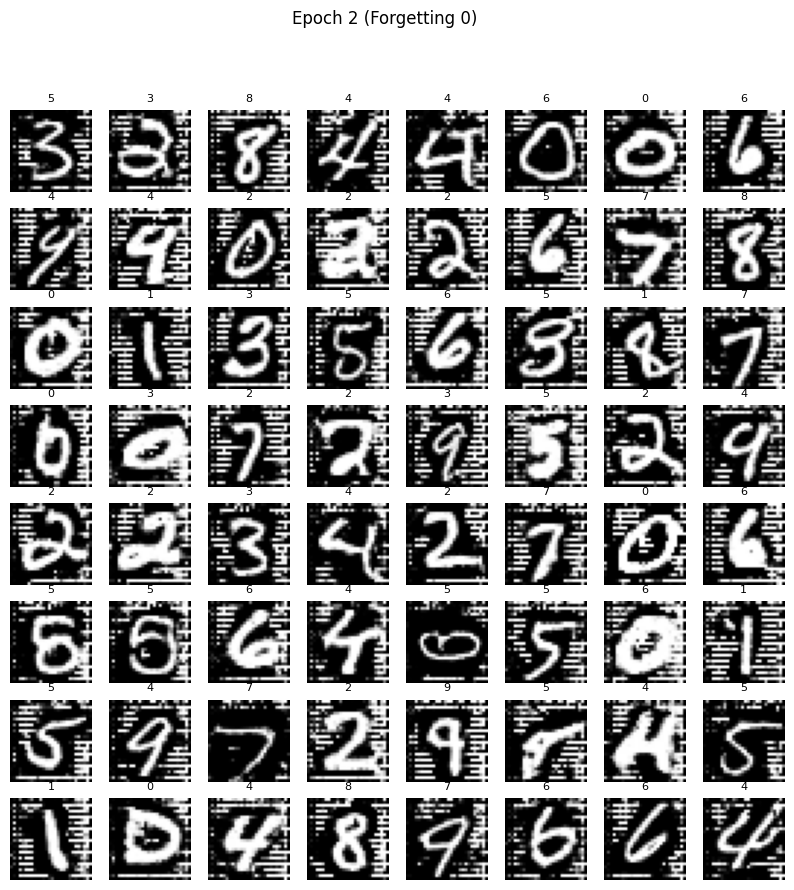

[E3 S0] kept 241/256
[E3 S100] kept 244/256
[E3 S200] kept 245/256
[E3 S300] kept 242/256
[Epoch 3] % Digit 0 = 5.23%


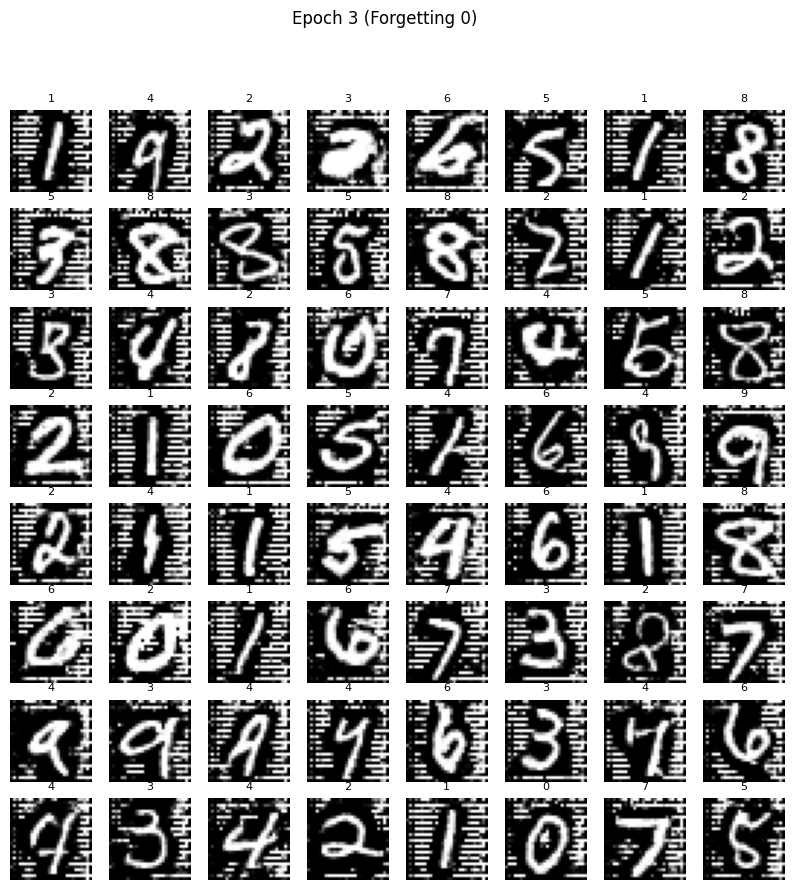

[E4 S0] kept 243/256
[E4 S100] kept 238/256


In [ ]:
def to28(x):
    return F.interpolate(x, size=(28,28),
                         mode="bilinear",
                         align_corners=False)

clf.eval()
netG.eval()

N = 5000
preds_all = []

with torch.no_grad():
    for _ in range(N // 128):
        z = torch.randn(128, 100, 1, 1).to(device)
        fake = netG(z)
        fake28 = to28(fake)
        preds = clf(fake28).argmax(1)
        preds_all.extend(preds.cpu().numpy())

preds_all = np.array(preds_all)
for d in range(10):
    print(f"{d}: {(preds_all==d).mean()*100:.2f}%")

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

device = "cuda"

def to28(x):
    """Resize 64×64 GAN output to 28×28 for classifier."""
    return F.interpolate(x, size=(28,28),
                         mode="bilinear",
                         align_corners=False)

forget_digit = 0
epochs = 30
batch_size = 256
nz = 100

criterion = nn.BCEWithLogitsLoss()

optG = torch.optim.Adam(netG.parameters(), lr=2e-4, betas=(0.5,0.999))
optD = torch.optim.Adam(netD.parameters(), lr=2e-4, betas=(0.5,0.999))

forget_percentages = []

for epoch in range(epochs):

    for step in range(400):

        z = torch.randn(batch_size, nz, 1, 1, device=device)
        fake = netG(z)

        fake28 = to28(fake)
        with torch.no_grad():
            preds = clf(fake28).argmax(1)

        keep_mask = (preds != forget_digit)

        if keep_mask.sum() == 0:
            continue

        fake_filtered = fake[keep_mask]


        netD.zero_grad()

        real_imgs, _ = next(iter(train_loader))
        real_imgs = F.interpolate(real_imgs, size=(64,64)).to(device)

        D_real = netD(real_imgs).view(-1)
        loss_real = criterion(D_real, torch.ones_like(D_real))

        D_fake = netD(fake_filtered.detach()).view(-1)
        loss_fake = criterion(D_fake, torch.zeros_like(D_fake))

        loss_D = loss_real + loss_fake
        loss_D.backward()
        optD.step()

        netG.zero_grad()

        D_fake_new = netD(fake_filtered).view(-1)
        loss_G = criterion(D_fake_new, torch.ones_like(D_fake_new))

        loss_G.backward()
        optG.step()

        if step % 100 == 0:
            print(f"[E{epoch+1} S{step}] kept {keep_mask.sum().item()}/{batch_size}")

    with torch.no_grad():
        z_test = torch.randn(3000, nz, 1, 1, device=device)
        fake_test = netG(z_test)
        fake_test28 = to28(fake_test)
        preds_test = clf(fake_test28).argmax(1)
        zero_ratio = (preds_test == forget_digit).float().mean().item()

    forget_percentages.append(zero_ratio)
    print(f"[Epoch {epoch+1}] % Digit 0 = {zero_ratio*100:.2f}%")

    with torch.no_grad():
        z_vis = torch.randn(64, nz, 1, 1, device=device)
        fake_vis = netG(z_vis)
        fake_vis28 = to28(fake_vis)
        labels_vis = clf(fake_vis28).argmax(1).cpu().numpy()

    plt.figure(figsize=(10,10))
    for i in range(64):
        plt.subplot(8,8,i+1)
        plt.imshow(fake_vis28[i][0].cpu(), cmap="gray")
        plt.title(str(labels_vis[i]), fontsize=8)
        plt.axis("off")
    plt.suptitle(f"Epoch {epoch+1} (Forgetting 0)")
    plt.show()

plt.plot(range(1, epochs+1),
         [p*100 for p in forget_percentages],
         marker='o')
plt.title("Percent of Digit 0 Generated Over Training")
plt.xlabel("Epoch")
plt.ylabel("% Zero")
plt.grid(True)
plt.show()

